In [2]:
import jieba
import pandas as pd

with open('data/stopwords-master/Stopwords.txt', 'r', encoding='utf-8') as f:
    stopwords = set([line.strip() for line in f.readlines()])
with open('data/词频分析.txt', 'r', encoding='utf-8') as f:
    documents = f.readlines()
def preprocess(text, stopwords):
    words = jieba.cut(text)
    filtered_words = [word for word in words if word not in stopwords and len(word) >= 2 and word != '\t' and not word.isdigit()]
    return filtered_words
word_counts = {}
for doc in documents:
    words = preprocess(doc, stopwords)
    for word in words:
        if word not in word_counts:
            word_counts[word] = 1
        else:
            word_counts[word] += 1
word_freq_df = pd.DataFrame(list(word_counts.items()), columns=['Word', 'Frequency'])
word_freq_df = word_freq_df.sort_values(by='Frequency', ascending=False)
word_freq_df=word_freq_df.head(100)
word_freq_df.to_csv('word_frequency.csv', index=False, encoding='utf-8')

Building prefix dict from the default dictionary ...
Loading model from cache /var/folders/5h/mj91n3v53z99zl4kcr9sp1k80000gn/T/jieba.cache
Loading model cost 1.816 seconds.
Prefix dict has been built successfully.


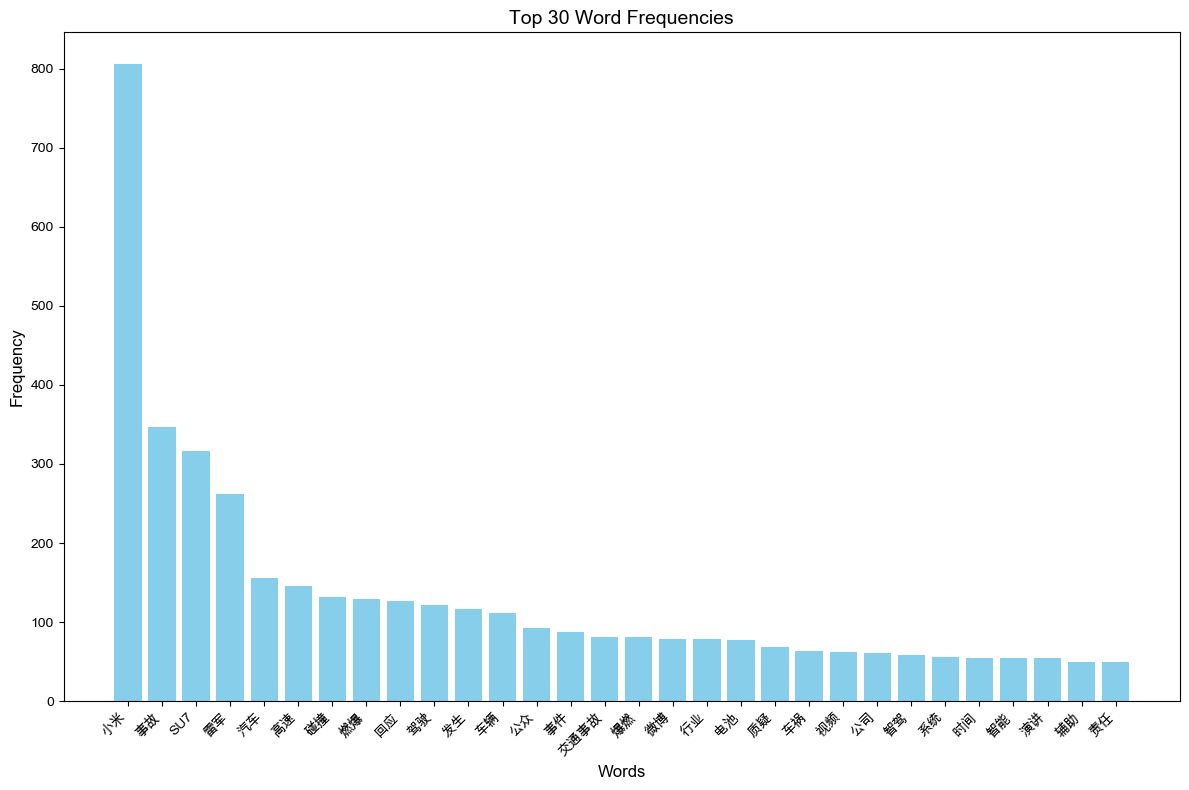

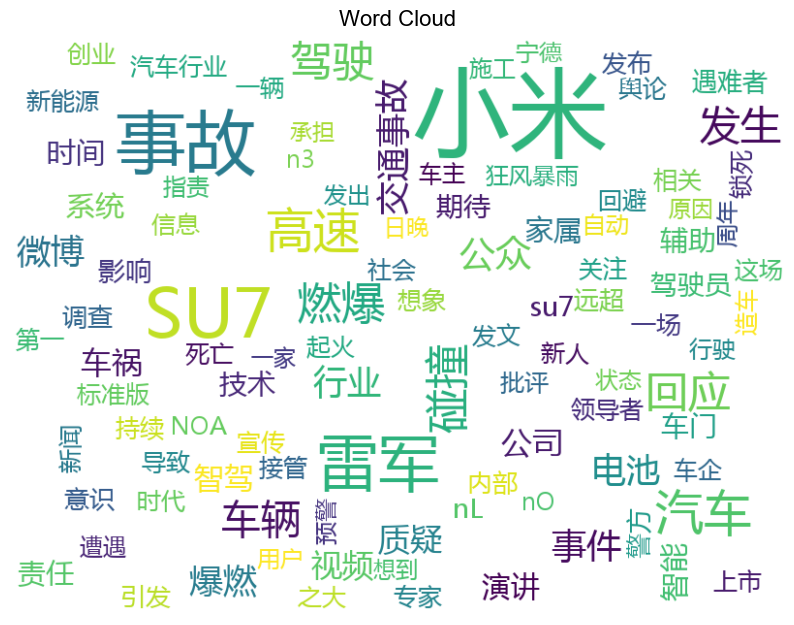

In [5]:
import jieba
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import numpy as np
from collections import Counter

# 加载停用词
with open('data/stopwords-master/Stopwords.txt', 'r', encoding='utf-8') as f:
    stopwords = set([line.strip() for line in f.readlines()])

# 加载文本数据
with open('data/词频分析.txt', 'r', encoding='utf-8') as f:
    documents = f.readlines()

# 预处理函数
def preprocess(text, stopwords):
    words = jieba.cut(text)
    filtered_words = [word for word in words if word not in stopwords and len(word) >= 2 and word != '\t' and not word.isdigit()]
    return filtered_words

# 统计词频
word_counts = Counter()
for doc in documents:
    words = preprocess(doc, stopwords)
    word_counts.update(words)

# 转换为DataFrame
word_freq_df = pd.DataFrame(word_counts.most_common(), columns=['Word', 'Frequency'])

# 保存为CSV文件
word_freq_df.head(100).to_csv('word_frequency.csv', index=False, encoding='utf-8')

font_path = "data/fonts/msyh.ttf"

# 设置 Matplotlib 的字体和负号显示
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']  # macOS,用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号

# 可视化：生成柱状图
plt.figure(figsize=(12, 8))
plt.bar(word_freq_df['Word'][:30], word_freq_df['Frequency'][:30], color='skyblue')
plt.xlabel('Words', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Top 30 Word Frequencies', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('word_frequency_bar.png')
plt.show()

# 可视化：生成词云图
wordcloud = WordCloud(
    font_path=font_path,  # 设置字体路径，确保支持中文
    background_color='white',  # 背景颜色
    width=800,
    height=600,
    max_words=100,  # 最大显示的词数
    min_font_size=10,  # 最小字体大小
    max_font_size=100,  # 最大字体大小
).generate_from_frequencies(word_counts)

# 显示词云图
plt.figure(figsize=(10, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud', fontsize=16)
plt.savefig('word_cloud.png')
plt.show()
